# 05 — Tune, choose the threshold, final test, explain, save
Order (SRS checklist steps 8–11): tune XGBoost with CV → choose the minimum-cost threshold on out-of-fold training predictions → fit on all training data → **touch the test set once** → SHAP → save.

In [1]:
import json
import sys
import time
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.metrics import ConfusionMatrixDisplay, average_precision_score, classification_report
from sklearn.model_selection import RandomizedSearchCV, cross_val_predict

from src import config
from src.evaluate import cost_curve, meets_goal, metrics_at, no_model_cost, total_cost
from src.preprocess import load_data, train_test
from src.train import build_pipeline, cv_splitter

df = load_data(verbose=False)
X_train, X_test, y_train, y_test = train_test(df)
config.MODELS_DIR.mkdir(parents=True, exist_ok=True)

## Which model goes forward?

In [2]:
allres = pd.read_csv(config.RESULTS_DIR / "cv_results_all.csv")
best = allres.loc[allres.groupby("model").pr_auc_mean.idxmax()].sort_values("pr_auc_mean", ascending=False)
print(best[["model", "technique", "pr_auc_mean", "pr_auc_std"]].to_string(index=False))

      model            technique  pr_auc_mean  pr_auc_std
        xgb                 none     0.848042    0.026457
         rf                 none     0.836547    0.032999
         lr         class_weight     0.754437    0.026451
        mlp         class_weight     0.718813    0.038338
autoencoder anomaly (legit only)     0.254963    0.031843
      dummy                 none     0.001665    0.000000


## Step 8 — Tune XGBoost (RandomizedSearchCV, scoring = PR-AUC)

In [3]:
default_cv = allres.query("model == 'xgb' and technique == 'none'").pr_auc_mean.item()
param_dist = {
    "model__n_estimators": [200, 300, 500],
    "model__max_depth": [2, 3, 4, 5],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__subsample": [0.7, 0.8, 1.0],
    "model__colsample_bytree": [0.6, 0.8, 1.0],
    "model__min_child_weight": [1, 3, 5, 10],
    "model__reg_lambda": [1, 5, 10],
    "model__scale_pos_weight": [1, 3, 10],
}
start = time.time()
search = RandomizedSearchCV(build_pipeline("xgb", "none"), param_dist, n_iter=15,
                            scoring="average_precision", cv=cv_splitter(), refit=False,
                            return_train_score=True, random_state=config.SEED, n_jobs=1)
search.fit(X_train, y_train)
cvr = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
top = cvr.iloc[0]
print(f"Search took {time.time() - start:.0f}s")
print(f"Default XGB CV PR-AUC: {default_cv:.4f}")
print(f"Tuned   XGB CV PR-AUC: {top.mean_test_score:.4f} ± {top.std_test_score:.4f} "
      f"(train {top.mean_train_score:.4f}, gap {top.mean_train_score - top.mean_test_score:.3f})")
print("Best params:", search.best_params_)
cvr[["mean_test_score", "std_test_score", "mean_train_score"] + [c for c in cvr if c.startswith("param_")]].head(5)

Search took 308s
Default XGB CV PR-AUC: 0.8480
Tuned   XGB CV PR-AUC: 0.8507 ± 0.0240 (train 0.9998, gap 0.149)
Best params: {'model__subsample': 1.0, 'model__scale_pos_weight': 10, 'model__reg_lambda': 10, 'model__n_estimators': 300, 'model__min_child_weight': 10, 'model__max_depth': 5, 'model__learning_rate': 0.1, 'model__colsample_bytree': 1.0}


,mean_test_score,std_test_score,mean_train_score,param_model__subsample,param_model__scale_pos_weight,param_model__reg_lambda,param_model__n_estimators,param_model__min_child_weight,param_model__max_depth,param_model__learning_rate,param_model__colsample_bytree
10,0.850742,0.024030,0.999786,1.0,10,10,300,10,5,0.10,1.0
0,0.850147,0.027668,1.000000,0.8,10,1,500,3,4,0.10,0.8
6,0.850008,0.025054,0.994645,0.8,1,1,300,3,5,0.05,0.8
4,0.849270,0.025538,0.994871,0.8,10,10,200,10,4,0.10,1.0
5,0.846019,0.026195,0.964460,0.8,1,5,500,5,3,0.05,0.8


In [4]:
gain = top.mean_test_score - default_cv
if top.mean_test_score >= default_cv:
    final_params = search.best_params_
    print(f"Using tuned params (gain {gain:+.4f}).")
else:
    final_params = {}
    print(f"Tuning did not beat the default (gain {gain:+.4f}); keeping default params.")
if abs(gain) < config.MIN_PR_AUC_GAIN:
    print("Stop rule: gain < 0.01 PR-AUC, so no further tuning — more training will not help.")

Using tuned params (gain +0.0027).
Stop rule: gain < 0.01 PR-AUC, so no further tuning — more training will not help.


## Step 9 — Choose the threshold by business cost
Out-of-fold probabilities on training data only. Cost(t) = Σ Amount of missed frauds + C_FP × false alarms, with C_FP = 5 (assumption).

In [5]:
def final_pipeline():
    return build_pipeline("xgb", "none").set_params(**final_params)

oof = cross_val_predict(final_pipeline(), X_train, y_train, cv=cv_splitter(), method="predict_proba")[:, 1]
curve = cost_curve(y_train, oof, X_train["Amount"])
baseline_cost = no_model_cost(y_train, X_train["Amount"])

unconstrained = curve.loc[curve.cost.idxmin()]
feasible = curve[(curve.recall >= config.TARGET_RECALL) & (curve.precision >= config.TARGET_PRECISION)]
chosen = feasible.loc[feasible.cost.idxmin()] if len(feasible) else unconstrained
THRESHOLD = float(chosen.threshold)

print(f"No model (approve everything): cost {baseline_cost:,.0f}")
print(f"Minimum-cost threshold: {unconstrained.threshold:.2f} -> cost {unconstrained.cost:,.0f}, "
      f"precision {unconstrained.precision:.3f}, recall {unconstrained.recall:.3f}")
print(f"Chosen threshold (min cost that also meets the goal): {THRESHOLD:.2f} -> cost {chosen.cost:,.0f}, "
      f"precision {chosen.precision:.3f}, recall {chosen.recall:.3f}")
print(f"Cost at default 0.50: {curve.loc[curve.threshold == 0.5, 'cost'].item():,.0f}")
print(f"Money saved vs no model (training CV): {baseline_cost - chosen.cost:,.0f} "
      f"({(baseline_cost - chosen.cost) / baseline_cost:.0%})")

No model (approve everything): cost 43,825
Minimum-cost threshold: 0.08 -> cost 9,847, precision 0.706, recall 0.857
Chosen threshold (min cost that also meets the goal): 0.08 -> cost 9,847, precision 0.706, recall 0.857
Cost at default 0.50: 11,214
Money saved vs no model (training CV): 33,978 (78%)


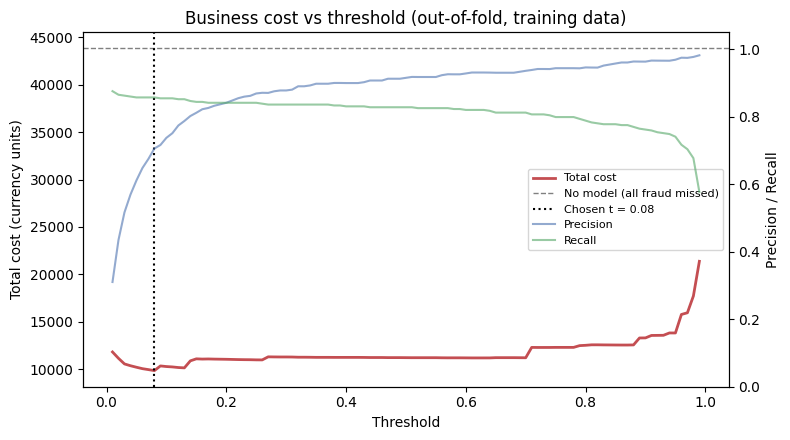

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(curve.threshold, curve.cost, color="#c44e52", lw=2, label="Total cost")
ax.axhline(baseline_cost, color="grey", ls="--", lw=1, label="No model (all fraud missed)")
ax.axvline(THRESHOLD, color="black", ls=":", lw=1.5, label=f"Chosen t = {THRESHOLD:.2f}")
ax.set(xlabel="Threshold", ylabel="Total cost (currency units)", title="Business cost vs threshold (out-of-fold, training data)")
ax2 = ax.twinx()
ax2.plot(curve.threshold, curve.precision, color="#4c72b0", alpha=0.6, label="Precision")
ax2.plot(curve.threshold, curve.recall, color="#55a868", alpha=0.6, label="Recall")
ax2.set_ylim(0, 1.05); ax2.set_ylabel("Precision / Recall")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="center right", fontsize=8)
fig.tight_layout(); fig.savefig(config.FIGURES_DIR / "05_cost_vs_threshold.png", dpi=150); plt.show()

## Robustness check: time-based split (training data only)
Fit on the earliest 80% of training transactions, score the latest 20%. If PR-AUC is close to the stratified CV score, the model is not just memorising one time period.

In [7]:
order = X_train["Time"].sort_values().index
cut = int(len(order) * 0.8)
early, late = order[:cut], order[cut:]
tb = final_pipeline().fit(X_train.loc[early], y_train.loc[early])
tb_proba = tb.predict_proba(X_train.loc[late])[:, 1]
tb_m = metrics_at(y_train.loc[late], tb_proba, THRESHOLD)
print(f"Time-based PR-AUC: {tb_m['pr_auc']:.4f} (stratified CV: {top.mean_test_score if final_params else default_cv:.4f}) "
      f"| recall {tb_m['recall']:.3f} | precision {tb_m['precision']:.3f} | frauds in late slice: {int(y_train.loc[late].sum())}")

Time-based PR-AUC: 0.8135 (stratified CV: 0.8507) | recall 0.812 | precision 0.703 | frauds in late slice: 64


## Step 10 — Final test (only once)

In [8]:
final = final_pipeline().fit(X_train, y_train)
proba_test = final.predict_proba(X_test)[:, 1]
test_m = metrics_at(y_test, proba_test, THRESHOLD)
test_cost = total_cost(y_test, proba_test, X_test["Amount"], THRESHOLD)
test_no_model = no_model_cost(y_test, X_test["Amount"])

print(classification_report(y_test, (proba_test >= THRESHOLD).astype(int), target_names=["Legit", "Fraud"], digits=3))
print(f"PR-AUC {test_m['pr_auc']:.4f} | ROC-AUC {test_m['roc_auc']:.4f}")
print(f"Recall {test_m['recall']:.3f} | Precision {test_m['precision']:.3f} | goal met: {meets_goal(test_m['precision'], test_m['recall'])}")
print(f"Frauds caught {test_m['tp']} of {test_m['tp'] + test_m['fn']} | false alarms {test_m['fp']} of {test_m['fp'] + test_m['tn']:,} legit")
print(f"Cost: no model {test_no_model:,.0f} -> model {test_cost:,.0f} | saved {test_no_model - test_cost:,.0f} "
      f"({(test_no_model - test_cost) / test_no_model:.0%})")

              precision    recall  f1-score   support

       Legit      1.000     0.999     1.000     56651
       Fraud      0.726     0.811     0.766        95

    accuracy                          0.999     56746
   macro avg      0.863     0.905     0.883     56746
weighted avg      0.999     0.999     0.999     56746

PR-AUC 0.8167 | ROC-AUC 0.9731
Recall 0.811 | Precision 0.726 | goal met: True
Frauds caught 77 of 95 | false alarms 29 of 56,651 legit
Cost: no model 14,766 -> model 3,479 | saved 11,288 (76%)


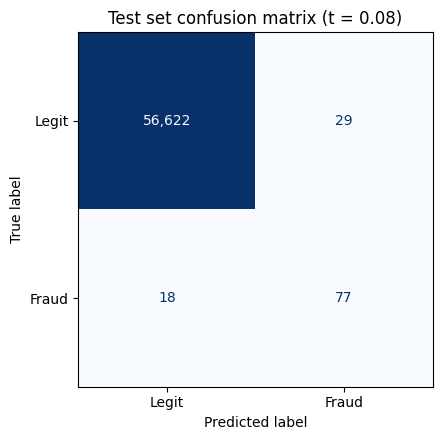

In [9]:
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, (proba_test >= THRESHOLD).astype(int),
                                        display_labels=["Legit", "Fraud"], cmap="Blues", values_format=",", ax=ax, colorbar=False)
ax.set_title(f"Test set confusion matrix (t = {THRESHOLD:.2f})")
fig.tight_layout(); fig.savefig(config.FIGURES_DIR / "05_confusion_matrix_test.png", dpi=150); plt.show()

## Step 11 — Explain with SHAP
V1–V28 are anonymised PCA components, so explanations name components (e.g. "V14 pushed risk up"), not business terms.

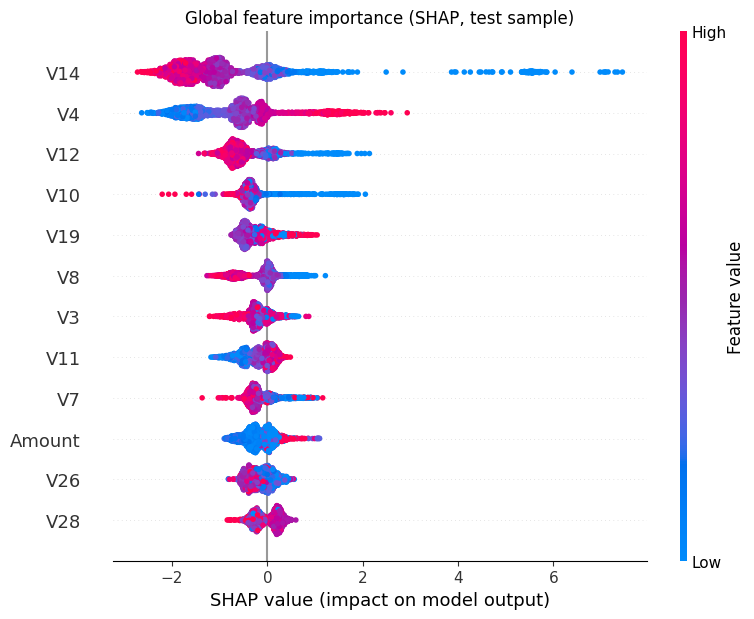

In [10]:
pre, model = final.named_steps["scale"], final.named_steps["model"]
names = list(pre.get_feature_names_out())
Xt_test = pd.DataFrame(pre.transform(X_test), columns=names, index=X_test.index)
explainer = shap.TreeExplainer(model)

rng = np.random.RandomState(config.SEED)
idx = np.concatenate([np.where(y_test.values == 1)[0], rng.choice(np.where(y_test.values == 0)[0], 3000, replace=False)])
sv = explainer(Xt_test.iloc[idx])
shap.summary_plot(sv, Xt_test.iloc[idx], show=False, max_display=12)
plt.title("Global feature importance (SHAP, test sample)")
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / "05_shap_summary.png", dpi=150, bbox_inches="tight"); plt.show()

Explaining test transaction 83108: P(fraud) = 0.993, Amount = 5.91


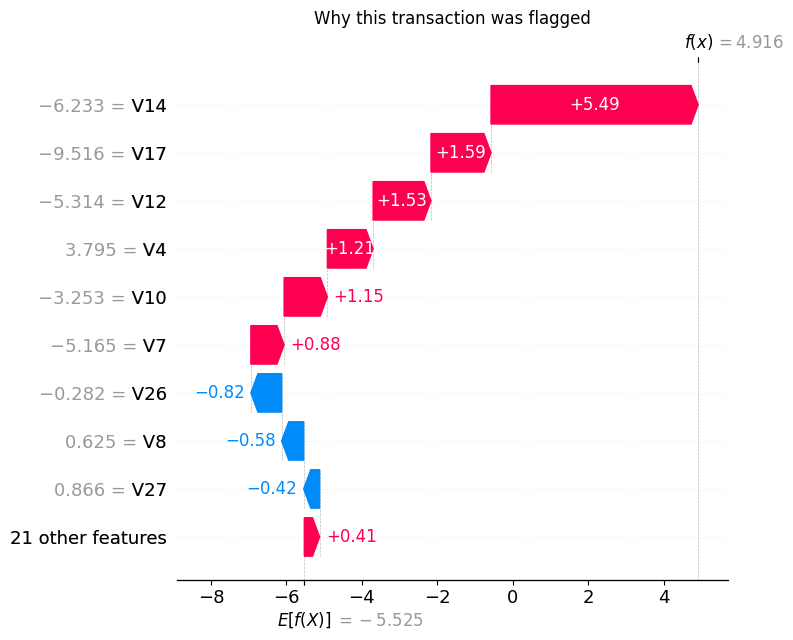

In [11]:
caught = np.where((y_test.values == 1) & (proba_test >= THRESHOLD))[0]
one = caught[len(caught) // 2]
print(f"Explaining test transaction {X_test.index[one]}: P(fraud) = {proba_test[one]:.3f}, Amount = {X_test.iloc[one]['Amount']:.2f}")
shap.plots.waterfall(explainer(Xt_test.iloc[[one]])[0], max_display=10, show=False)
plt.title("Why this transaction was flagged")
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / "05_shap_waterfall_fraud.png", dpi=150, bbox_inches="tight"); plt.show()

## Save artifacts
The whole pipeline (scaler + model) is saved as one file, so the app cannot scale twice. This replaces the separate `scaler.joblib` from the SRS.

In [12]:
joblib.dump(final, config.MODELS_DIR / "best_model.joblib")
meta = {
    "model": "XGBoost", "threshold": THRESHOLD, "c_fp": config.C_FP,
    "params": {k.replace("model__", ""): v for k, v in final_params.items()},
    "feature_order": list(X_train.columns),
    "cv_pr_auc": float(top.mean_test_score if final_params else default_cv),
    "test": {k: (float(v) if isinstance(v, float) else v) for k, v in test_m.items()},
    "test_cost": float(test_cost), "test_no_model_cost": float(test_no_model),
}
(config.MODELS_DIR / "threshold.json").write_text(json.dumps(meta, indent=2))

# Small set of test transactions for the live demo: every test fraud + 300 random legit.
demo_idx = np.concatenate([np.where(y_test.values == 1)[0], rng.choice(np.where(y_test.values == 0)[0], 300, replace=False)])
demo = X_test.iloc[demo_idx].assign(Class=y_test.iloc[demo_idx].values)
demo.to_csv(config.ROOT / "app" / "demo_samples.csv", index_label="row_id")
print(json.dumps({k: meta[k] for k in ["model", "threshold", "cv_pr_auc", "params"]}, indent=2))

{
  "model": "XGBoost",
  "threshold": 0.08,
  "cv_pr_auc": 0.8507419023247571,
  "params": {
    "subsample": 1.0,
    "scale_pos_weight": 10,
    "reg_lambda": 10,
    "n_estimators": 300,
    "min_child_weight": 10,
    "max_depth": 5,
    "learning_rate": 0.1,
    "colsample_bytree": 1.0
  }
}


## Software tests (SRS 11.2): reload, known cases, latency

In [13]:
reloaded = joblib.load(config.MODELS_DIR / "best_model.joblib")
same = np.array_equal(reloaded.predict_proba(X_test)[:, 1], proba_test)
print(f"Reload test: identical predictions = {same}")

fraud_row = X_test.iloc[[caught[0]]]
legit_row = X_test.iloc[[np.where((y_test.values == 0) & (proba_test < THRESHOLD))[0][0]]]
print(f"Known fraud flagged: {reloaded.predict_proba(fraud_row)[0, 1] >= THRESHOLD} | "
      f"known legit approved: {reloaded.predict_proba(legit_row)[0, 1] < THRESHOLD}")

t0 = time.perf_counter()
for _ in range(50):
    reloaded.predict_proba(X_test.iloc[[0]])
print(f"Latency per prediction: {(time.perf_counter() - t0) / 50 * 1000:.1f} ms (target < 1000 ms)")
assert same

Reload test: identical predictions = True
Known fraud flagged: True | known legit approved: True


Latency per prediction: 4.4 ms (target < 1000 ms)
